In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nColumns with missing values:")
print(df.columns[df.isnull().any()].tolist())

Missing values in each column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


In [8]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nColumns with missing values:")
print(df.columns[df.isnull().any()].tolist)

Missing values in each column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
<bound method IndexOpsMixin.tolist of Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='str')>


In [17]:
df = df.copy()
for column in df.select_dtypes(include="number").columns:
    df[column] = df[column].fillna(df[column].median())
for column in df.select_dtypes(include=["object", "string"]).columns:
    if df[column].isnull().any():
        mode_value = df[column].mode()
        if len(mode_value) > 0:
            df[column] = df[column].fillna(mode_value[0])
df = df.dropna(subset=["pickup", "fare", "pickup_borough","payment", "distance", "tip","tolls", "total"])
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


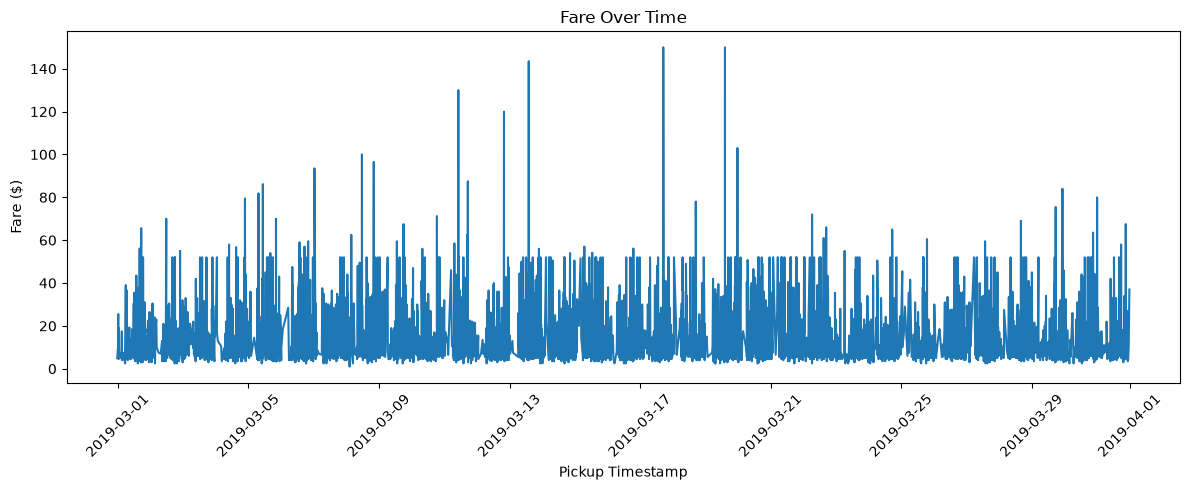

In [21]:
df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")
line_data = df.dropna(subset=["pickup", "fare"]).sort_values("pickup")
plt.figure(figsize=(12, 5))
plt.plot(line_data["pickup"], line_data["fare"])
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.title("Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

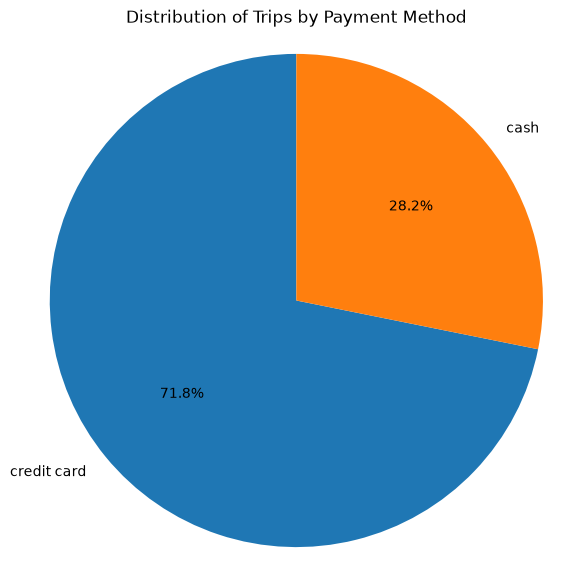

In [23]:
payment_counts = df["payment"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(payment_counts,labels=payment_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Distribution of Trips by Payment Method")
plt.axis("equal")
plt.show()

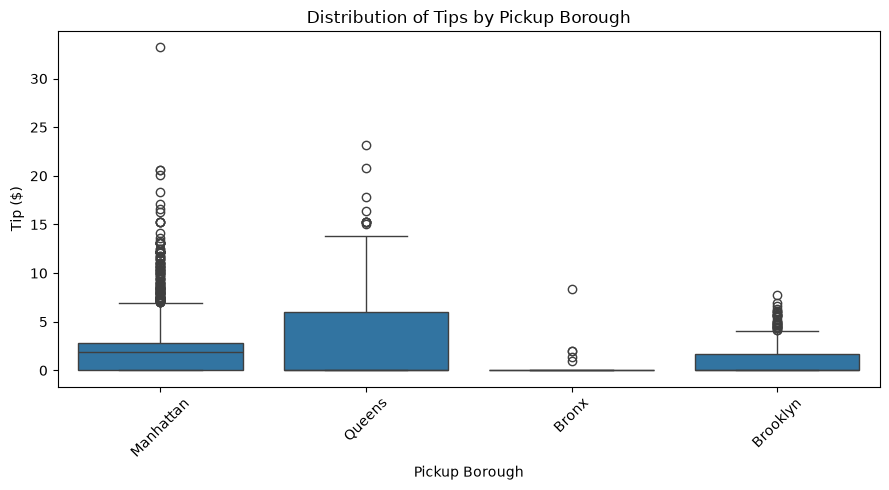

In [31]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="pickup_borough", y="tip")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.title("Distribution of Tips by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

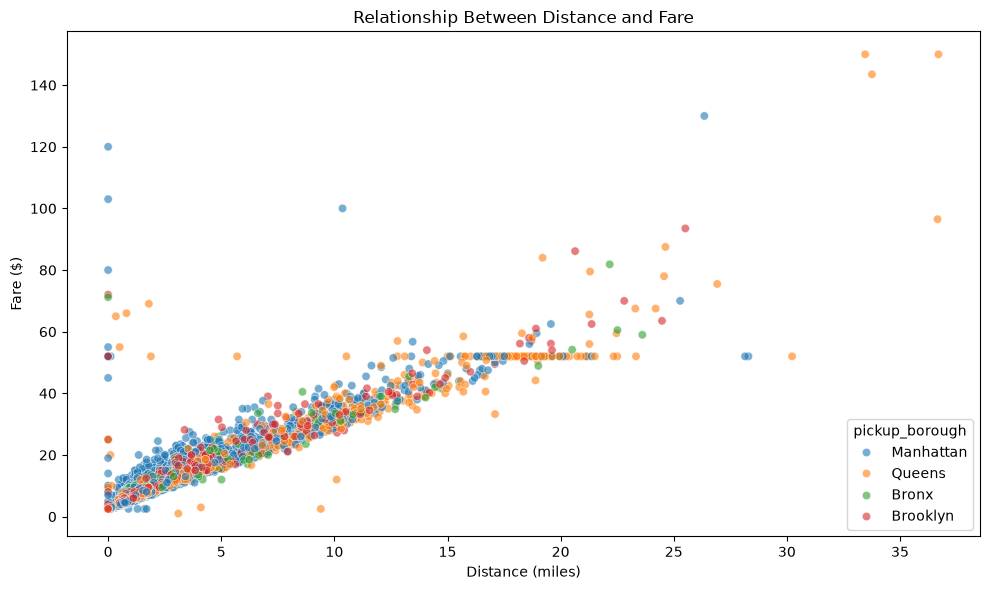

In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough",alpha=0.6)
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.title("Relationship Between Distance and Fare")
plt.tight_layout()
plt.show()

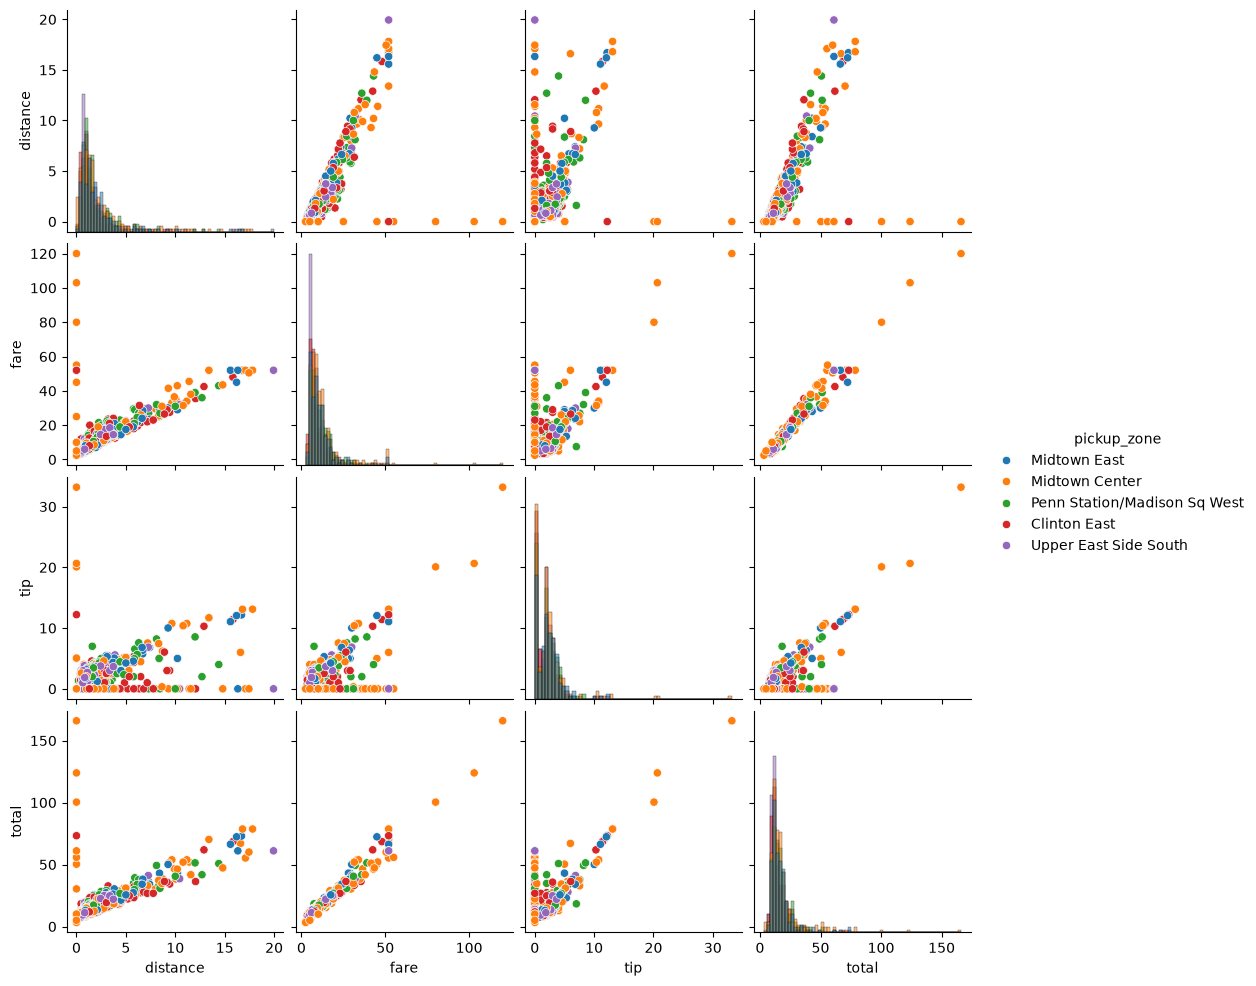

In [46]:
top_zones = df["pickup_zone"].value_counts().head(5).index
pair_data = df[df["pickup_zone"].isin(top_zones)]
pair_data = pair_data[["distance", "fare", "tip", "total", "pickup_zone"]].dropna()
sns.pairplot(pair_data,vars=["distance", "fare", "tip", "total"],hue="pickup_zone",diag_kind="hist")
plt.show()

In [54]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=df,x="payment",y="fare")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.title("Fare Distribution by Payment Method")
plt.tight_layout()
plt.show()

SyntaxError: invalid syntax (1119575455.py, line 1)